# Household electricity consumption

Explore the UCI household power consumption dataset and forecast daily average active power. Place `household_power_consumption.txt` in this directory before running. The raw data is not included in the repository. Dependencies: pandas, NumPy, Matplotlib, statsmodels, and scikit-learn.

The last 60 days are split into 30 days for validation and 30 days for testing. Model selection uses validation only; the selected model is refit through the end of validation before its test forecast.

Days with no readings are filled with the previous day’s average so the forecast has a regular daily index.

**Data:** [UCI Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption). Extract `household_power_consumption.txt` into this lesson folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
from sklearn.metrics import mean_absolute_error, mean_squared_error

raw = pd.read_csv("household_power_consumption.txt", sep=";", na_values="?", low_memory=False)
raw["datetime"] = pd.to_datetime(raw["Date"] + " " + raw["Time"], dayfirst=True)
raw = raw.drop(columns=["Date", "Time"]).set_index("datetime").sort_index()
print(f"Rows: {len(raw):,}; missing active-power values: {raw['Global_active_power'].isna().sum():,}")
daily = raw["Global_active_power"].resample("D").mean().ffill().dropna()
print(f"Daily observations: {len(daily):,}; period: {daily.index.min().date()} to {daily.index.max().date()}")

Rows: 2,075,259; missing active-power values: 25,979
Daily observations: 1,442; period: 2006-12-16 to 2010-11-26


## Daily trend and seasonality

The centered moving average and decomposition below describe the full historical series. They are not features used for forecasting.

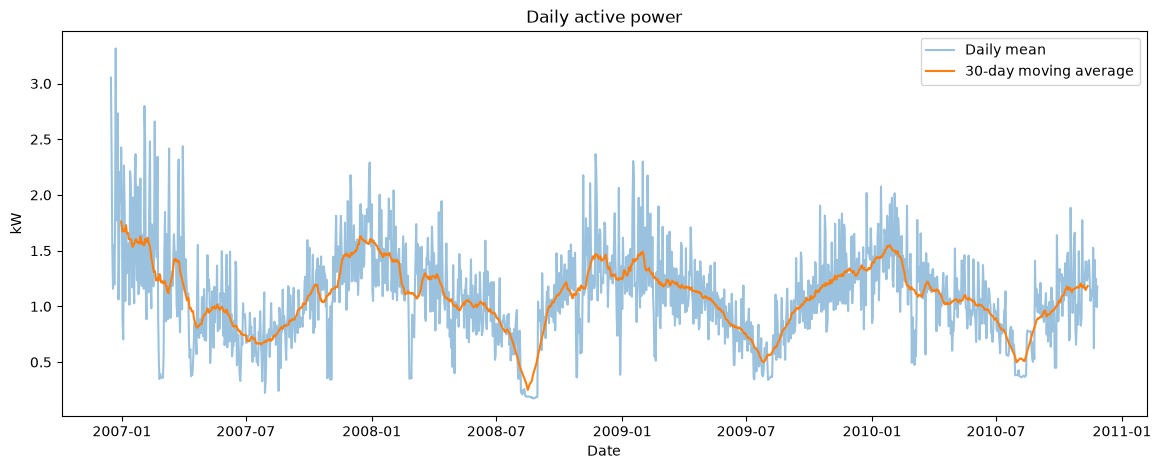

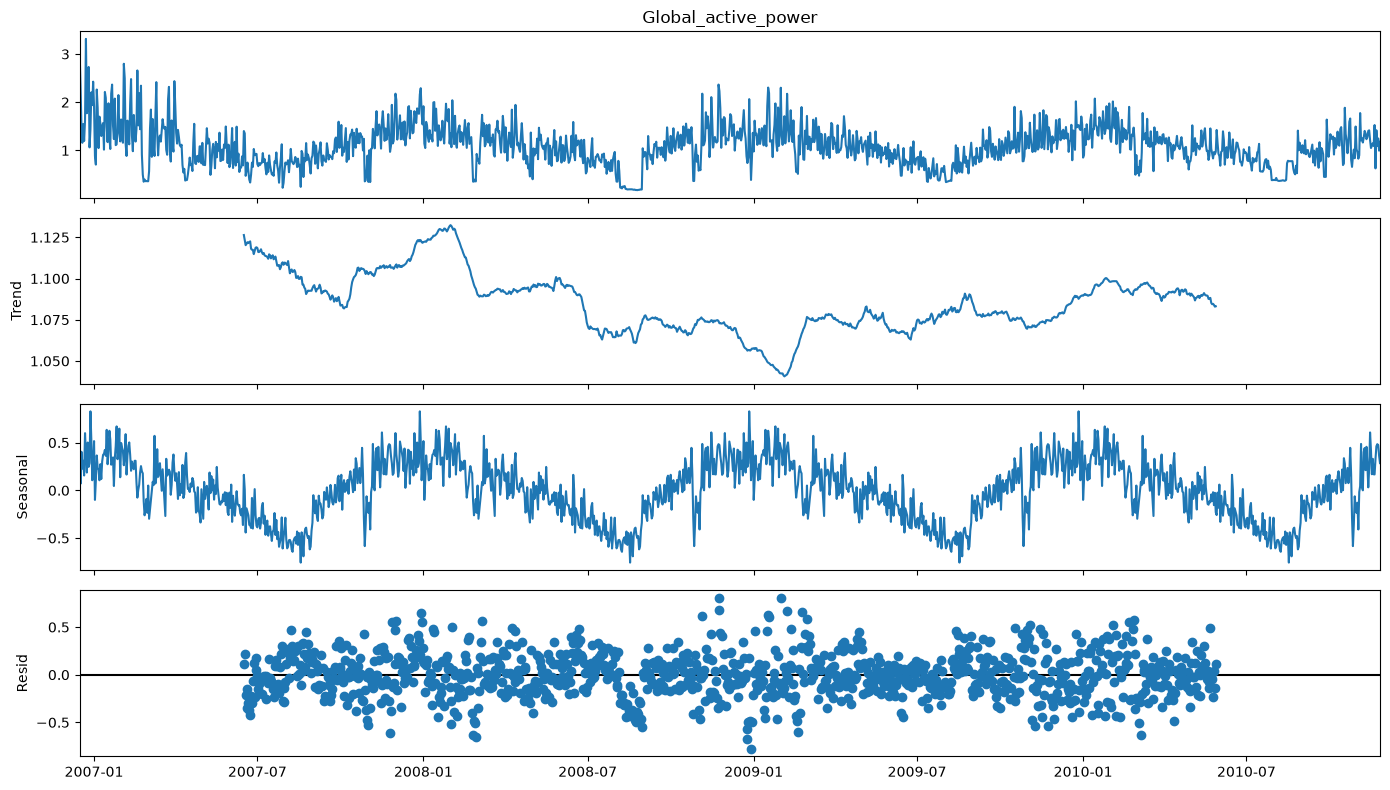

In [2]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily, alpha=0.45, label="Daily mean")
ax.plot(daily.rolling(30, center=True).mean(), label="30-day moving average")
ax.set(title="Daily active power", ylabel="kW", xlabel="Date")
ax.legend()
plt.show()

decomposition = seasonal_decompose(daily, model="additive", period=365)
fig = decomposition.plot()
fig.set_size_inches(14, 8)
plt.tight_layout()
plt.show()

## Hourly patterns and low-consumption days

Hourly averages and the bottom 2% of daily values are descriptive summaries of the full dataset; unusually low values do not establish their cause.

/var/folders/pp/nnh10rws3jl0kc34jz4381080000gn/T/ipykernel_26030/82897000.py:1: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  hourly = raw["Global_active_power"].groupby([raw.index.dayofweek, raw.index.hour]).mean().unstack()


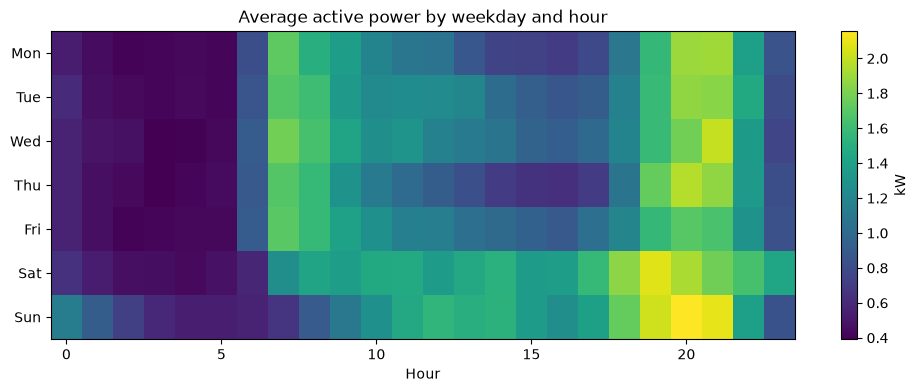

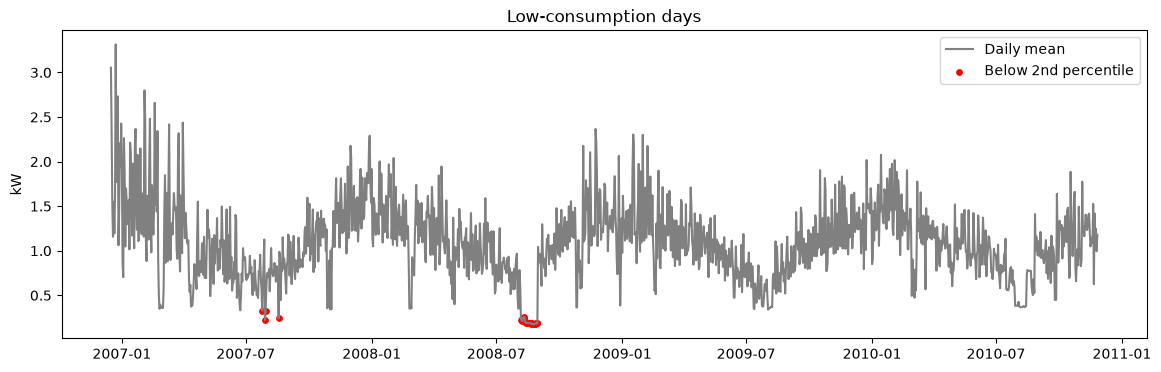

In [3]:
hourly = raw["Global_active_power"].groupby([raw.index.dayofweek, raw.index.hour]).mean().unstack()
fig, ax = plt.subplots(figsize=(12, 4))
image = ax.imshow(hourly, aspect="auto", cmap="viridis")
ax.set(yticks=range(7), yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], xlabel="Hour", title="Average active power by weekday and hour")
fig.colorbar(image, ax=ax, label="kW")
plt.show()

threshold = daily.quantile(0.02)
low = daily[daily < threshold]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily, color="gray", label="Daily mean")
ax.scatter(low.index, low, color="red", s=15, label="Below 2nd percentile")
ax.set(ylabel="kW", title="Low-consumption days")
ax.legend()
plt.show()

## Compare forecasts on the validation period

Compare a fixed-parameter simple exponential smoother with damped Holt trend. The lower validation MAE selects the model; the final 30 days remain untouched until evaluation.

In [4]:
train, validation, test = daily.iloc[:-60], daily.iloc[-60:-30], daily.iloc[-30:]

def fit_model(name, values):
    if name == "Simple exponential smoothing":
        return SimpleExpSmoothing(values, initialization_method="estimated").fit(
            smoothing_level=0.2, optimized=False)
    return Holt(values, initialization_method="estimated", damped_trend=True).fit(
        smoothing_level=0.3, smoothing_trend=0.05, damping_trend=0.98, optimized=False)

names = ["Simple exponential smoothing", "Damped Holt"]
validation_mae = {}
for name in names:
    forecast = fit_model(name, train).forecast(len(validation))
    validation_mae[name] = mean_absolute_error(validation, forecast)
    print(f"{name} validation MAE: {validation_mae[name]:.4f} kW")
selected = min(validation_mae, key=validation_mae.get)
print(f"Selected: {selected}")

Simple exponential smoothing validation MAE: 0.4829 kW
Damped Holt validation MAE: 0.7379 kW
Selected: Simple exponential smoothing


## Final test forecast

Test MAE: 0.2072 kW; RMSE: 0.2614 kW


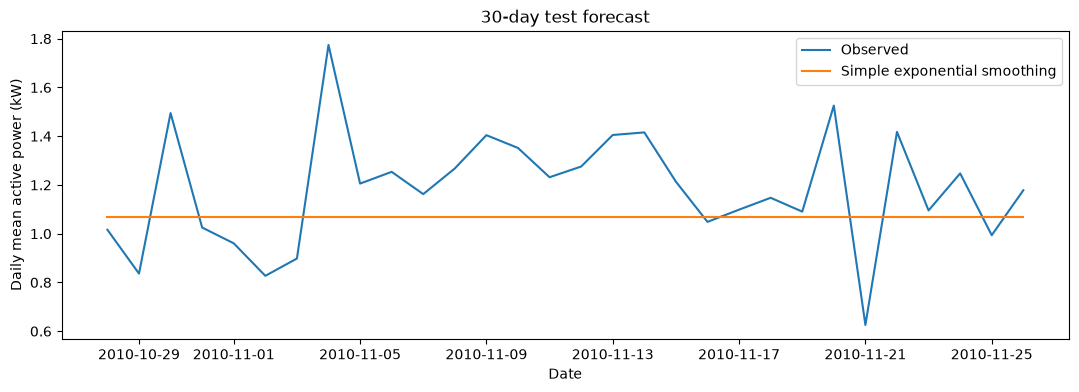

In [5]:
model = fit_model(selected, pd.concat([train, validation]))
forecast = model.forecast(len(test))
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
print(f"Test MAE: {mae:.4f} kW; RMSE: {rmse:.4f} kW")
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test.index, test, label="Observed")
ax.plot(test.index, forecast, label=selected)
ax.set(title="30-day test forecast", ylabel="Daily mean active power (kW)", xlabel="Date")
ax.legend()
plt.show()